# Gráficos com Matplotlib nos datasets `paises.csv` e `space.csv`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

paises = pd.read_csv('paises.csv', sep=';')
paises['Country'] = paises['Country'].str.strip()
paises['Region'] = paises['Region'].str.strip()

space = pd.read_csv('space.csv', sep=';')
space.columns = space.columns.str.strip()

print(f'paises.csv: {paises.shape[0]} países e {paises.shape[1]} colunas')
print(f'space.csv: {space.shape[0]} missões e {space.shape[1]} colunas')

paises.csv: 227 países e 20 colunas
space.csv: 4324 missões e 8 colunas


## Questão 1

Por meio do dataset `paises.csv`, trace dois gráficos de linhas em um mesmo plano cartesiano, um mostrando a taxa de mortalidade (*Deathrate*) e outro a taxa de natalidade (*Birthrate*) dos países da América do Norte.

             Country  Birthrate  Deathrate
             Bermuda      11.40       7.74
              Canada      10.78       7.80
           Greenland      15.93       7.84
St Pierre & Miquelon      13.52       6.83
       United States      14.14       8.26


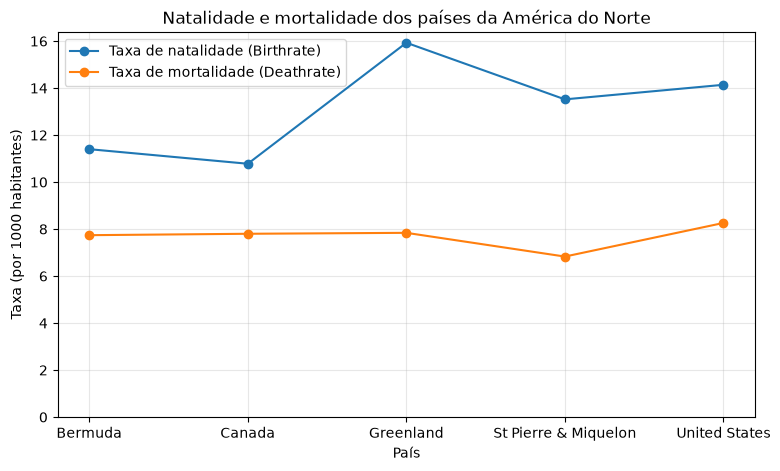

In [2]:
america_norte = paises[paises['Region'] == 'NORTHERN AMERICA']

print(america_norte[['Country', 'Birthrate', 'Deathrate']].to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(america_norte['Country'], america_norte['Birthrate'], marker='o', label='Taxa de natalidade (Birthrate)')
plt.plot(america_norte['Country'], america_norte['Deathrate'], marker='o', label='Taxa de mortalidade (Deathrate)')

plt.title('Natalidade e mortalidade dos países da América do Norte')
plt.xlabel('País')
plt.ylabel('Taxa (por 1000 habitantes)')
plt.ylim(0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Questão 2

Por meio do dataset `space.csv`, usando `subplot()`, trace dois gráficos de barras separados lado a lado: à esquerda, as 5 empresas com mais missões de sucesso; à direita, as 5 empresas com mais missões de falha.

5 empresas com mais missões de sucesso:
Company Name
RVSN USSR           1614
Arianespace          269
CASC                 231
General Dynamics     203
VKS RF               188

5 empresas com mais missões de falha:
Company Name
RVSN USSR           121
General Dynamics     37
US Air Force         30
CASC                 14
US Navy              14


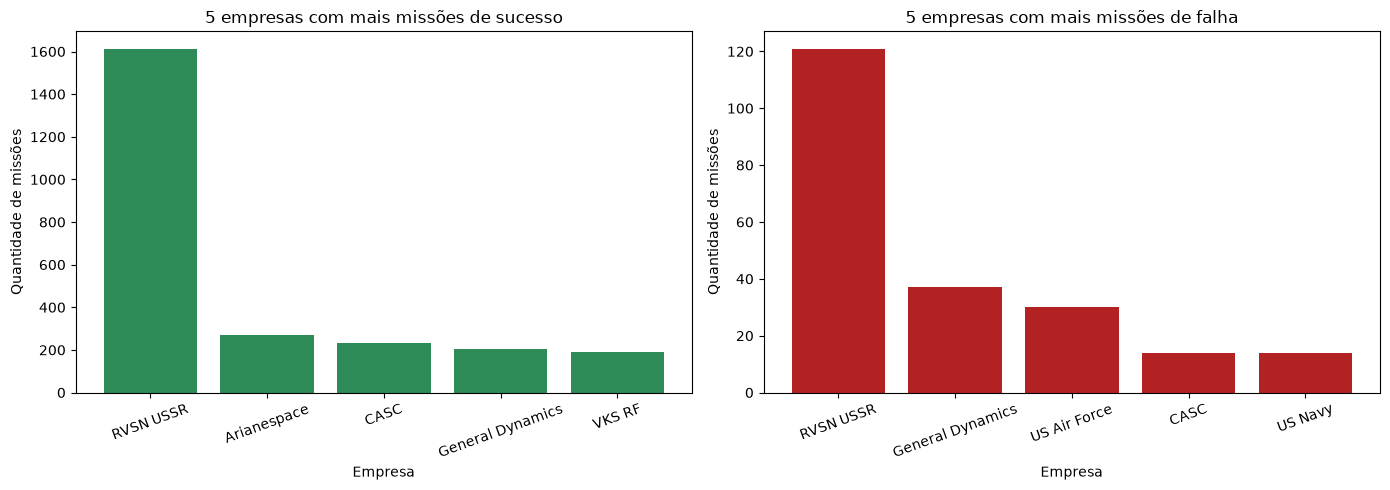

In [3]:
sucessos = space[space['Status Mission'] == 'Success']['Company Name'].value_counts().head(5)
falhas = space[space['Status Mission'] == 'Failure']['Company Name'].value_counts().head(5)

print('5 empresas com mais missões de sucesso:')
print(sucessos.to_string())
print('\n5 empresas com mais missões de falha:')
print(falhas.to_string())

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.bar(sucessos.index, sucessos.values, color='seagreen')
plt.title('5 empresas com mais missões de sucesso')
plt.xlabel('Empresa')
plt.ylabel('Quantidade de missões')
plt.xticks(rotation=20)

plt.subplot(1, 2, 2)
plt.bar(falhas.index, falhas.values, color='firebrick')
plt.title('5 empresas com mais missões de falha')
plt.xlabel('Empresa')
plt.ylabel('Quantidade de missões')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## Questão 3

Por meio do dataset `space.csv`, trace um gráfico em torta ilustrando a porcentagem de missões da empresa Roscosmos que deram certo e que deram errado.

Missões da Roscosmos: 55
Deram certo: 51 (92.73%)
Deram errado: 4 (7.27%)


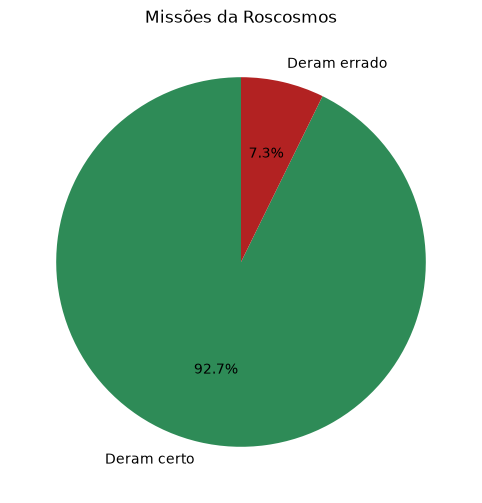

In [4]:
roscosmos = space[space['Company Name'] == 'Roscosmos']

deram_certo = (roscosmos['Status Mission'] == 'Success').sum()
deram_errado = (roscosmos['Status Mission'] != 'Success').sum()

print(f'Missões da Roscosmos: {len(roscosmos)}')
print(f'Deram certo: {deram_certo} ({deram_certo / len(roscosmos) * 100:.2f}%)')
print(f'Deram errado: {deram_errado} ({deram_errado / len(roscosmos) * 100:.2f}%)')

plt.figure(figsize=(6, 6))
plt.pie(
    [deram_certo, deram_errado],
    labels=['Deram certo', 'Deram errado'],
    colors=['seagreen', 'firebrick'],
    autopct='%1.1f%%',
    startangle=90,
)
plt.title('Missões da Roscosmos')
plt.show()

## Questão 4

Utilizando o dataset `space.csv`, trace um gráfico em barras com as 5 empresas que mais tiveram missões com status "Failure", usando uma cor customizada.

5 empresas com mais missões com status "Failure":
Company Name
RVSN USSR           121
General Dynamics     37
US Air Force         30
CASC                 14
US Navy              14


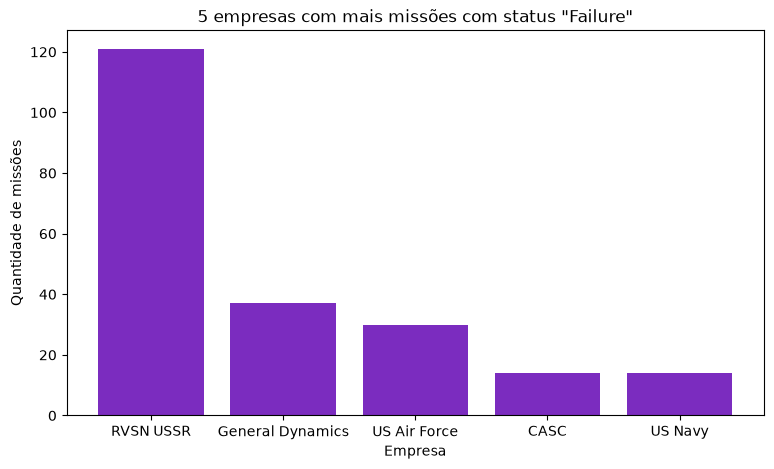

In [5]:
mais_falhas = space[space['Status Mission'] == 'Failure']['Company Name'].value_counts().head(5)

print('5 empresas com mais missões com status "Failure":')
print(mais_falhas.to_string())

plt.figure(figsize=(9, 5))
plt.bar(mais_falhas.index, mais_falhas.values, color='#7B2CBF')

plt.title('5 empresas com mais missões com status "Failure"')
plt.xlabel('Empresa')
plt.ylabel('Quantidade de missões')
plt.show()

## Questão 5

Por meio do dataset `paises.csv`, trace um gráfico de dispersão (scatter) relacionando a Renda per Capita (GDP) com a Taxa de Alfabetização (Literacy %) dos países da América Latina, fazendo com que o tamanho de cada ponto represente a população do país.

Países da América Latina no gráfico: 44
Fora do gráfico por não ter o dado de alfabetização: Virgin Islands


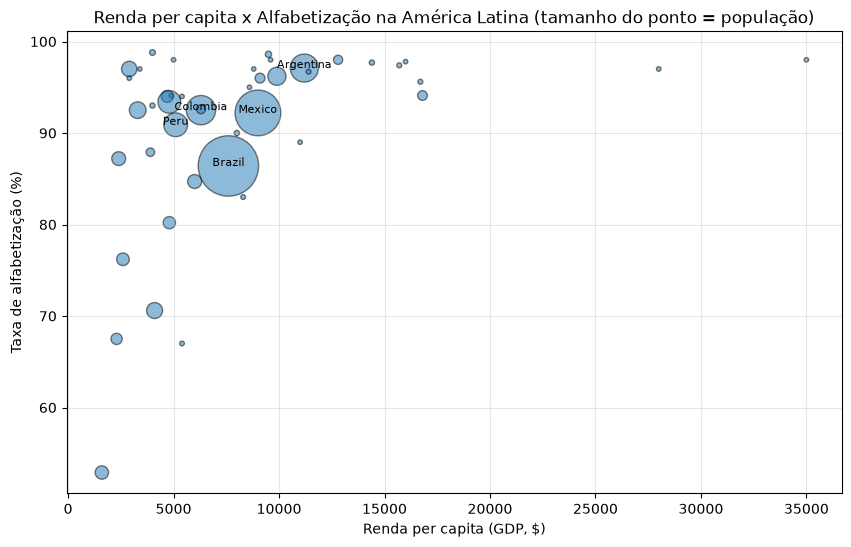

In [6]:
america_latina = paises[paises['Region'] == 'LATIN AMER. & CARIB']

sem_dado = america_latina[america_latina['Literacy (%)'] == 0]
america_latina = america_latina[america_latina['Literacy (%)'] > 0]

print(f'Países da América Latina no gráfico: {len(america_latina)}')
print(f"Fora do gráfico por não ter o dado de alfabetização: {', '.join(sem_dado['Country'])}")

plt.figure(figsize=(10, 6))
plt.scatter(
    america_latina['GDP ($ per capita)'],
    america_latina['Literacy (%)'],
    s=america_latina['Population'] / 100000 + 10,
    alpha=0.5,
    edgecolors='black',
)

for _, pais in america_latina.nlargest(5, 'Population').iterrows():
    plt.annotate(pais['Country'], (pais['GDP ($ per capita)'], pais['Literacy (%)']), ha='center', fontsize=8)

plt.title('Renda per capita x Alfabetização na América Latina (tamanho do ponto = população)')
plt.xlabel('Renda per capita (GDP, $)')
plt.ylabel('Taxa de alfabetização (%)')
plt.grid(True, alpha=0.3)
plt.show()